# USP5 pKd — Fuzzy Dual-Step

**Dual-step** = dua tahap berurutan: (1) partisi fuzzy Fuzzy C-Means pada ruang laten PCA; (2) pakar lokal berbobot keanggotaan (F1) dan koreksi residu fuzzy atas Model 1 (F2), lalu penggabungan Lagrange (F3).
Semua dipelajari hanya dari data latih tiap fold; seed seleksi dipisah dari seed verifikasi; skema random bebas-duplikat dan scaffold dipakai seperti tahap sebelumnya.

In [1]:
import os, sys, time, warnings, pickle, itertools
warnings.filterwarnings("ignore")
IN_NB = "get_ipython" in globals()
import matplotlib
if not IN_NB:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np, pandas as pd
from joblib import Parallel, delayed
from scipy.stats import pearsonr, spearmanr, skew

from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import Descriptors, rdFingerprintGenerator, MACCSkeys
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.Scaffolds import MurckoScaffold
RDLogger.DisableLog("rdApp.*")

from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, ExtraTreesRegressor
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import KFold, GroupKFold, StratifiedShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.decomposition import PCA

OUT = "hasil_usp5_fuzzy"; os.makedirs(OUT, exist_ok=True)
CSV = "USP5_prediksi_per_senyawa.csv"
SEED = 42
N_JOBS = 2

# --- gaya grafik (dataviz): permukaan terang, tinta gelap, marka tipis, label langsung
INK, MUTED, GRID, SURF = "#0b0b0b", "#6b6b6b", "#e4e4e1", "#fcfcfb"
C_BASE, C_M1, C_M2, C_UN, C_M3 = "#9a9a9a", "#2a78d6", "#eb6834", "#8a63d2", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": .6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9.5, "legend.frameon": False, "figure.dpi": 100, "savefig.dpi": 200,
})
MODELS = ["Baseline", "Model 1", "Model 2", "Union", "Model 3"]
COL = {"Baseline": C_BASE, "Model 1": C_M1, "Model 2": C_M2, "Union": C_UN, "Model 3": C_M3}
FIGS = []
def finish(fig, name):
    fig.savefig(f"{OUT}/{name}.png", bbox_inches="tight"); FIGS.append(name)
    if IN_NB: plt.show()
    else: plt.close(fig)

def metrics(yt, yp):
    return dict(R2=r2_score(yt, yp), RMSE=float(np.sqrt(mean_squared_error(yt, yp))),
                MAE=mean_absolute_error(yt, yp),
                Pearson=pearsonr(yt, yp)[0] if np.std(yp) > 0 else np.nan,
                Spearman=spearmanr(yt, yp)[0] if np.std(yp) > 0 else np.nan)

import rdkit, sklearn
print("python", sys.version.split()[0], "| rdkit", rdkit.__version__, "| sklearn", sklearn.__version__)

python 3.13.18 | rdkit 2026.09.2 | sklearn 1.9.1


## 1. Data: pemuatan, standardisasi, scaffold

CSV berisi satu SMILES yang berupa garam kalium (`CHEMBL5266862`, `[K+]`), beberapa SMILES bermuatan/stereo, dan satu
peptida. Semua model dilatih pada **struktur yang distandardkan sama**: fragmen terbesar -> netralisasi -> SMILES kanonik.
Scaffold = Bemis-Murcko tanpa stereokimia, dipakai sebagai grup pada scaffold-CV.

In [2]:
raw = pd.read_csv(CSV)
chooser, unch = rdMolStandardize.LargestFragmentChooser(), rdMolStandardize.Uncharger()
def standardize(smi):
    m = Chem.MolFromSmiles(smi)
    m = unch.uncharge(chooser.choose(m))
    return m
mols = [standardize(s) for s in raw.smiles]
assert all(m is not None for m in mols)
raw["smi_std"] = [Chem.MolToSmiles(m) for m in mols]
def scaf(m):
    try:
        s = MurckoScaffold.GetScaffoldForMol(m)
        return Chem.MolToSmiles(s, isomericSmiles=False) or "NOSCAF"
    except Exception:
        return "NOSCAF"
raw["scaf_std"] = [scaf(m) for m in mols]
y = raw["pKd_eksperimen"].to_numpy(float)
groups = pd.factorize(raw["scaf_std"])[0]
n = len(y)
n_changed = int((raw.smiles != raw.smi_std).sum())
print(f"n = {n} | SMILES unik setelah standardisasi: {raw.smi_std.nunique()} | scaffold unik: {len(set(groups))} "
      f"(CSV: {raw.scaffold.nunique()}) | SMILES berubah oleh standardisasi: {n_changed}")
print(f"pKd: {y.min():.3f}-{y.max():.3f} | mean {y.mean():.3f} | SD {y.std(ddof=1):.3f} | pKd>5: {(y>5).sum()}")
sc_counts = pd.Series(groups).value_counts()
print(f"scaffold terbesar: {sc_counts.iloc[0]} senyawa | scaffold berisi 1 senyawa: {(sc_counts==1).sum()}")

n = 80 | SMILES unik setelah standardisasi: 79 | scaffold unik: 38 (CSV: 38) | SMILES berubah oleh standardisasi: 1
pKd: 3.031-5.553 | mean 4.122 | SD 0.637 | pKd>5: 9
scaffold terbesar: 23 senyawa | scaffold berisi 1 senyawa: 30


**Temuan data penting:** setelah standardisasi, `CHEMBL5266862` (garam K+) dan `CHEMBL5278336` ternyata **molekul yang sama**
(asam bebas; pKd 5,51 vs 5,55) — jadi "80 SMILES unik" sebenarnya 79 struktur unik. Pada random-CV, salah satu pasangan ini
hampir pasti berada di training saat yang lain diuji, sehingga sedikit menaikkan R² random (keduanya senyawa pKd > 5). Pada scaffold-CV
keduanya berada di scaffold yang sama sehingga tidak bocor. Angka disajikan apa adanya (80 baris, konsisten dengan Model 1 dan 2).

## 2. Featurisasi (dua keluarga blok, mengikuti Model 1 dan Model 2)

- **Model 1:** `DESC1` (217 deskriptor RDKit, NaN/inf -> 0), `MOR1` (Morgan *count* r=2, 1024), `MAC1` (MACCS 167).
- **Model 2:** `DESC2` (deskriptor tanpa NaN, varians > 0, |r| <= 0.95), `FP2` (Morgan biner, bit aktif pada >= 4 molekul),
  `MAC2` (MACCS yang bervariasi).

Filter `DESC2/FP2/MAC2` bersifat *tanpa label* (tidak memakai y), dihitung pada seluruh 80 senyawa seperti di notebook
asli Model 2. Semua praproses yang memakai y (SelectKBest, scaling berbasis training) berada **di dalam** pipeline per fold.

In [3]:
_names = [d[0] for d in Descriptors._descList]
mg_cnt = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
FEAT = {}
def featurize(mols_, fit=False):
    D = []
    for m in mols_:
        row = []
        for _, fn in Descriptors._descList:
            try: v = float(fn(m))
            except Exception: v = np.nan
            row.append(v)
        D.append(row)
    D = np.array(D, float); D[~np.isfinite(D)] = np.nan
    mor_c = np.array([mg_cnt.GetCountFingerprintAsNumPy(m) for m in mols_], float)
    mor_b = np.array([mg_cnt.GetFingerprintAsNumPy(m) for m in mols_], float)
    mac = np.array([np.array(MACCSkeys.GenMACCSKeys(m)) for m in mols_], float)
    if fit:
        Dd = pd.DataFrame(D, columns=_names)
        ok = (Dd.isna().sum() == 0) & (Dd.std() > 0); Dd = Dd.loc[:, ok]
        cm = Dd.corr().abs().to_numpy(); up = np.triu(np.ones(cm.shape), 1).astype(bool)
        drop = [(cm[:, i][up[:, i]] > .95).any() for i in range(cm.shape[1])]
        FEAT["desc2_cols"] = [c for c, d in zip(Dd.columns, drop) if not d]
        FEAT["fp2_mask"] = (mor_b > 0).sum(0) >= 4
        FEAT["mac2_mask"] = mac.std(0) > 0
    d1 = np.nan_to_num(D, nan=0.0)
    d2 = pd.DataFrame(D, columns=_names)[FEAT["desc2_cols"]].to_numpy()
    d2 = np.nan_to_num(d2, nan=0.0)
    fp2, mac2 = mor_b[:, FEAT["fp2_mask"]], mac[:, FEAT["mac2_mask"]]
    blocks = dict(DESC1=d1, MOR1=mor_c, MAC1=mac, DESC2=d2, FP2=fp2, MAC2=mac2)
    X = np.hstack(list(blocks.values()))
    idx, c = {}, 0
    for k, v in blocks.items():
        idx[k] = np.arange(c, c + v.shape[1]); c += v.shape[1]
    idx["FPMA"] = np.r_[idx["MOR1"], idx["MAC1"]]
    idx["DESCFP"] = np.r_[idx["DESC1"], idx["MOR1"]]
    idx["FPM2"] = np.r_[idx["FP2"], idx["MAC2"]]
    return X, idx
X, IDX = featurize(mols, fit=True)
print("X total:", X.shape)
for k in ["DESC1", "MOR1", "MAC1", "DESC2", "FP2", "MAC2", "FPMA", "DESCFP", "FPM2"]:
    print(f"  {k:7s} {len(IDX[k]):5d} kolom")

X total: (80, 1777)
  DESC1     217 kolom
  MOR1     1024 kolom
  MAC1      167 kolom
  DESC2     116 kolom
  FP2       137 kolom
  MAC2      116 kolom
  FPMA     1191 kolom
  DESCFP   1241 kolom
  FPM2      253 kolom


## 3. Perpustakaan anggota model

Sembilan anggota: tiga dari Model 1, tiga dari Model 2, dan tiga kandidat baru. Setiap ensemble adalah **rata-rata bobot sama**
dari prediksi anggotanya — identik secara matematis dengan `AverageBlend` (Model 1) dan `TanimotoBlend` (Model 2), tetapi
anggota hanya dilatih sekali per fold lalu dikombinasikan, sehingga semua kombinasi dievaluasi pada fold yang persis sama.

| Kunci | Anggota | Blok fitur |
|---|---|---|
| m1_br | BayesianRidge | Morgan-count+MACCS |
| m1_svr | SVR linear (C=0.3) | Morgan-count+MACCS |
| m1_gb | GradientBoosting (400, depth 3) | DESC+Morgan-count |
| m2_svr | SVR kernel Tanimoto (C=5) | FP2+MAC2 |
| m2_rf | RandomForest 300 | FP2+MAC2 |
| m2_rfm | RandomForest 300 | MAC2 |
| n_mm | SVR kernel **MinMax** (Tanimoto untuk fitur *count*) | Morgan-count+MACCS |
| n_et | ExtraTrees 300 | FP2+MAC2 |
| n_rfd | RandomForest 300 | DESC+Morgan-count |

In [4]:
class BlockSelector(BaseEstimator, TransformerMixin):
    def __init__(self, idx): self.idx = idx
    def fit(self, Xm, ym=None): return self
    def transform(self, Xm): return np.asarray(Xm)[:, self.idx]

def tanimoto_kernel(A, B):
    inter = A @ B.T
    return inter / ((A * A).sum(1)[:, None] + (B * B).sum(1)[None, :] - inter + 1e-12)

def minmax_kernel(A, B):
    num = np.minimum(A[:, None, :], B[None, :, :]).sum(2)
    den = np.maximum(A[:, None, :], B[None, :, :]).sum(2)
    return num / (den + 1e-12)

class KernelSVR(BaseEstimator, RegressorMixin):
    def __init__(self, kernel="tanimoto", C=5.0, epsilon=0.05):
        self.kernel = kernel; self.C = C; self.epsilon = epsilon
    def _k(self, A, B): return tanimoto_kernel(A, B) if self.kernel == "tanimoto" else minmax_kernel(A, B)
    def fit(self, Xm, ym):
        self.X_ = np.asarray(Xm, float)
        self.m_ = SVR(kernel="precomputed", C=self.C, epsilon=self.epsilon).fit(self._k(self.X_, self.X_), ym)
        return self
    def predict(self, Xm): return self.m_.predict(self._k(np.asarray(Xm, float), self.X_))

def pre1(k=None):  # praproses ala Model 1 (imputasi, varians nol, standardisasi)
    return [("imp", SimpleImputer(strategy="median")), ("vt", VarianceThreshold(0.0)), ("sc", StandardScaler())]
def pre2():        # praproses ala Model 2 untuk model kernel/pohon (varians nol saja)
    return [("vt", VarianceThreshold(0.0))]

LIB = {
 "m1_br":  ("M1 BayesianRidge",        "FPMA",   lambda: Pipeline([("pick", BlockSelector(IDX["FPMA"]))] + pre1() + [("m", BayesianRidge())])),
 "m1_svr": ("M1 SVR-linear",           "FPMA",   lambda: Pipeline([("pick", BlockSelector(IDX["FPMA"]))] + pre1() + [("m", SVR(kernel="linear", C=0.3, epsilon=0.05))])),
 "m1_gb":  ("M1 GradientBoosting",     "DESCFP", lambda: Pipeline([("pick", BlockSelector(IDX["DESCFP"]))] + pre1() + [("m", GradientBoostingRegressor(
               n_estimators=400, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=SEED))])),
 "m2_svr": ("M2 SVR-Tanimoto",         "FPM2",   lambda: Pipeline([("pick", BlockSelector(IDX["FPM2"]))] + pre2() + [("m", KernelSVR("tanimoto", 5.0))])),
 "m2_rf":  ("M2 RF (FP+MACCS)",        "FPM2",   lambda: Pipeline([("pick", BlockSelector(IDX["FPM2"]))] + pre2() + [("m", RandomForestRegressor(300, random_state=SEED, n_jobs=1))])),
 "m2_rfm": ("M2 RF (MACCS)",           "MAC2",   lambda: Pipeline([("pick", BlockSelector(IDX["MAC2"]))] + pre2() + [("m", RandomForestRegressor(300, random_state=SEED, n_jobs=1))])),
 "n_mm":   ("N SVR-MinMax (count)",    "FPMA",   lambda: Pipeline([("pick", BlockSelector(IDX["FPMA"]))] + pre2() + [("m", KernelSVR("minmax", 5.0))])),
 "n_et":   ("N ExtraTrees (FP+MACCS)", "FPM2",   lambda: Pipeline([("pick", BlockSelector(IDX["FPM2"]))] + pre2() + [("m", ExtraTreesRegressor(300, random_state=SEED, n_jobs=1))])),
 "n_rfd":  ("N RF (DESC+Morgan)",      "DESCFP", lambda: Pipeline([("pick", BlockSelector(IDX["DESCFP"]))] + pre2() + [("m", RandomForestRegressor(300, random_state=SEED, n_jobs=1))])),
}
KEYS = list(LIB)
M1_KEYS, M2_KEYS = ["m1_br", "m1_svr", "m1_gb"], ["m2_svr", "m2_rf", "m2_rfm"]
for k in KEYS: print(f"{k:7s} {LIB[k][0]:26s} blok {LIB[k][1]}")

m1_br   M1 BayesianRidge           blok FPMA
m1_svr  M1 SVR-linear              blok FPMA
m1_gb   M1 GradientBoosting        blok DESCFP
m2_svr  M2 SVR-Tanimoto            blok FPM2
m2_rf   M2 RF (FP+MACCS)           blok FPM2
m2_rfm  M2 RF (MACCS)              blok MAC2
n_mm    N SVR-MinMax (count)       blok FPMA
n_et    N ExtraTrees (FP+MACCS)    blok FPM2
n_rfd   N RF (DESC+Morgan)         blok DESCFP


## 4. Skema fold

- `R_sel` / `S_sel` (seed 100-104 / 200-204): hanya untuk **seleksi** Model 3.
- `R_ver` / `S_ver` (seed 700-704 / 800-804): hanya untuk **verifikasi** — tidak pernah dilihat saat seleksi.
- `R_rep` (seed 200-204): reproduksi protokol Model 1.
- `GKF`: `GroupKFold(5)` scaffold deterministik (Model 1, protokol B).
- `HO`: 20 split stratifikasi (kuartil pKd) 64 train / 16 test (Model 1, protokol C).

In [5]:
def folds_random(seed): return list(KFold(5, shuffle=True, random_state=seed).split(np.arange(n)))
def folds_scaffold(seed):
    ug = np.unique(groups); perm = np.random.RandomState(seed).permutation(len(ug))
    gmap = {g: perm[i] % 5 for i, g in enumerate(ug)}
    f = np.array([gmap[g] for g in groups])
    return [(np.where(f != k)[0], np.where(f == k)[0]) for k in range(5) if (f == k).sum() > 0]
SEEDS = dict(R_sel=[100, 101, 102, 103, 104], S_sel=[200, 201, 202, 203, 204],
             R_ver=[700, 701, 702, 703, 704], S_ver=[800, 801, 802, 803, 804], R_rep=[200, 201, 202, 203, 204])
FOLDS = {}
for g, ss in SEEDS.items():
    for s in ss:
        FOLDS[f"{g}:{s}"] = folds_scaffold(s) if g.startswith("S") else folds_random(s)
FOLDS["GKF:0"] = list(GroupKFold(5).split(X, y, groups=groups))
bins = np.digitize(y, np.quantile(y, [.25, .5, .75]))
HO_SPLITS = list(StratifiedShuffleSplit(n_splits=20, test_size=16, random_state=SEED).split(X, bins))
ov = sum(len(set(groups[tr]) & set(groups[te])) for tr, te in FOLDS["GKF:0"])
print(f"{len(FOLDS)} skema fold CV + {len(HO_SPLITS)} split hold-out | overlap scaffold GroupKFold = {ov} (harus 0)")
for i, (tr, te) in enumerate(FOLDS["S_ver:800"]):
    print(f"  scaffold-fold {i+1}: n_test={len(te):2d}  overlap_scaffold={len(set(groups[tr]) & set(groups[te]))}")

26 skema fold CV + 20 split hold-out | overlap scaffold GroupKFold = 0 (harus 0)
  scaffold-fold 1: n_test=18  overlap_scaffold=0
  scaffold-fold 2: n_test=16  overlap_scaffold=0
  scaffold-fold 3: n_test= 8  overlap_scaffold=0
  scaffold-fold 4: n_test=29  overlap_scaffold=0
  scaffold-fold 5: n_test= 9  overlap_scaffold=0


## 5. Audit praproses (metode ilmiah: ukur dulu, baru transformasi)

n                                 80.0000
n_duplikat_struktur                1.0000
pKd_min                            3.0315
pKd_max                            5.5528
pKd_SD                             0.6374
shapiro_p                          0.2253
y_outlier_MADz_gt3_5               0.0000
desc_nan_persen                    0.0000
desc_konstan                      59.0000
desc_skew_gt2_sebelum             62.0000
desc_skew_gt2_sesudah_winsor      39.0000
desc_median_skew_sebelum           1.2548
desc_median_skew_sesudah           0.7492
sel_outlier_desc_1_99            181.0000
morgan_kolom_nol                 583.0000
morgan_kolom_aktif_lt3           848.0000
kondisi_desc_terstandar         1436.2586
noise_ceiling_R2_sigma0_25         0.8461
noise_ceiling_R2_sigma0_30         0.7784


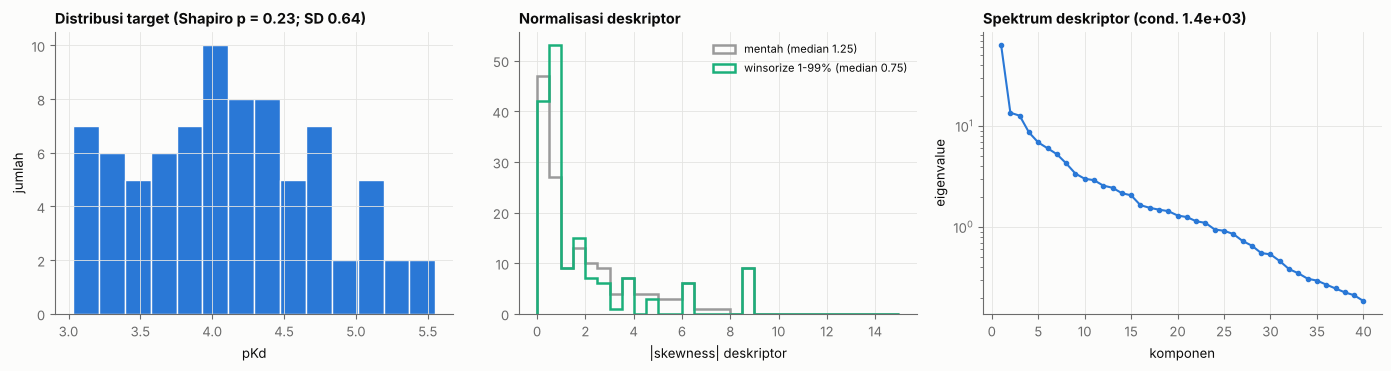

In [6]:
import warnings; warnings.filterwarnings("ignore")
import torch, torch.nn as nn
from scipy.stats import shapiro, probplot
sid = pd.factorize(raw["smi_std"])[0]
def group_folds(g, k, seed):
    ug = np.unique(g); perm = np.random.RandomState(seed).permutation(len(ug))
    gm = {u: perm[i] % k for i, u in enumerate(ug)}; f = np.array([gm[u] for u in g])
    return [(np.where(f != j)[0], np.where(f == j)[0]) for j in range(k) if (f == j).any()]
SEEDS["Rdd_sel"] = [100, 101, 102, 103, 104]; SEEDS["Rdd_ver"] = [700, 701, 702, 703, 704]
for g_ in ("Rdd_sel", "Rdd_ver"):
    for s in SEEDS[g_]: FOLDS[f"{g_}:{s}"] = group_folds(sid, 5, s)
D_all = X[:, IDX["DESC1"]]; M_all = X[:, IDX["MOR1"]]; A_all = X[:, IDX["MAC1"]]
mad = np.median(np.abs(y - np.median(y))) * 1.4826; zr = (y - np.median(y)) / mad
lo_, hi_ = np.nanpercentile(D_all, [1, 99], axis=0); n_out = int(((D_all < lo_) | (D_all > hi_)).sum())
Dv = np.nan_to_num(D_all)[:, np.nanstd(D_all, 0) > 0]; skD = np.abs(skew(Dv, axis=0)); Dc = np.clip(Dv, *np.percentile(Dv, [1, 99], axis=0)); skC = np.abs(skew(Dc, axis=0, nan_policy="omit"))
Zs = (Dc - Dc.mean(0)) / np.where(Dc.std(0) > 0, Dc.std(0), 1); sv = np.linalg.svd(np.nan_to_num(Zs), compute_uv=False); cond = sv[0] / sv[sv > 1e-8][-1]
AUD = dict(n=n, n_duplikat_struktur=int(n - len(np.unique(sid))), pKd_min=y.min(), pKd_max=y.max(), pKd_SD=y.std(ddof=1), shapiro_p=shapiro(y)[1], y_outlier_MADz_gt3_5=int((np.abs(zr) > 3.5).sum()),
           desc_nan_persen=100 * np.isnan(D_all).mean(), desc_konstan=int((np.nanstd(D_all, 0) == 0).sum()), desc_skew_gt2_sebelum=int((skD > 2).sum()), desc_skew_gt2_sesudah_winsor=int((skC > 2).sum()),
           desc_median_skew_sebelum=float(np.median(skD)), desc_median_skew_sesudah=float(np.nanmedian(skC)), sel_outlier_desc_1_99=n_out, morgan_kolom_nol=int((M_all.std(0) == 0).sum()), morgan_kolom_aktif_lt3=int(((M_all > 0).sum(0) < 3).sum()), kondisi_desc_terstandar=float(cond),
           noise_ceiling_R2_sigma0_25=1 - .25 ** 2 / y.var(ddof=1), noise_ceiling_R2_sigma0_30=1 - .30 ** 2 / y.var(ddof=1))
pd.Series(AUD).to_csv(f"{OUT}/audit_praproses.csv"); print(pd.Series(AUD).round(4).to_string())
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(y, bins=14, color=C_M1, edgecolor=SURF); ax[0].set(xlabel="pKd", ylabel="jumlah", title=f"Distribusi target (Shapiro p = {AUD['shapiro_p']:.2f}; SD {AUD['pKd_SD']:.2f})")
ax[1].hist(np.clip(skD, 0, 15), bins=np.linspace(0, 15, 31), histtype="step", lw=1.8, color=C_BASE, label=f"mentah (median {np.median(skD):.2f})"); ax[1].hist(np.clip(skC, 0, 15), bins=np.linspace(0, 15, 31), histtype="step", lw=1.8, color=C_M3, label=f"winsorize 1-99% (median {np.nanmedian(skC):.2f})")
ax[1].set(xlabel="|skewness| deskriptor", title="Normalisasi deskriptor"); ax[1].legend(fontsize=8)
ax[2].plot(np.arange(1, 41), np.linalg.svd(Zs, compute_uv=False)[:40] ** 2 / (n - 1), "-o", ms=3, color=C_M1); ax[2].set(yscale="log", xlabel="komponen", ylabel="eigenvalue", title=f"Spektrum deskriptor (cond. {cond:.1e})")
fig.tight_layout(); finish(fig, "01_audit_praproses")

## 6. Fuzzy Dual-Step

**Gagasan.** Ruang kimia senyawa USP5 tidak homogen: beberapa keluarga struktur berperilaku berbeda. Alih-alih satu model global, kita pakai
**partisi lunak (fuzzy)** sehingga setiap senyawa boleh "milik" beberapa kelompok sekaligus dengan derajat keanggotaan u ∈ [0,1], Σ_k u_k = 1.

- **Langkah 1 (partisi fuzzy):** Fuzzy C-Means (FCM, eksponen m) pada ruang laten PCA (8 komponen) dari [deskriptor | fingerprint] terstandar, dihitung **hanya dari data latih** tiap fold.
  Senyawa uji mendapat keanggotaan dari rumus FCM dengan pusat klaster tetap.
- **Langkah 2a — pakar lokal (F1):** satu Ridge per klaster, dilatih dengan bobot sampel u_ik^m; prediksi = Σ_k u_k(x) f_k(x).
- **Langkah 2b — koreksi residu fuzzy (F2):** Model 1 sebagai dasar; residual *out-of-fold bagian-dalam* r_i dirata-ratakan per klaster dengan bobot keanggotaan dan *shrinkage* τ:
  r̂(x) = Σ_k u_k(x) · Σ_i u_ik^m r_i / (Σ_i u_ik^m + τ). Prediksi = Model 1 + r̂. Ini analog kriging residu, tetapi dengan kernel keanggotaan fuzzy.
- **F3:** penggabungan Lagrange (varians minimum, tak-negatif) dari Model 1, F1, F2 — bobot dihitung dari seed seleksi saja.

Residual bagian-dalam dihitung dengan fold dalam yang sadar-grup (struktur untuk skema random, scaffold untuk skema scaffold) agar tidak terlalu optimistis.

In [7]:
from scipy.spatial.distance import cdist
from sklearn.linear_model import Ridge
class Pre2:
    def fit(self, Xtr):
        D = np.nan_to_num(Xtr[:, IDX["DESC1"]]); self.lo, self.hi = np.percentile(D, [1, 99], axis=0); D = np.clip(D, self.lo, self.hi); self.kd = D.std(0) > 0; self.md, self.sd_ = D.mean(0)[self.kd], D.std(0)[self.kd]
        F = np.hstack([np.log1p(Xtr[:, IDX["MOR1"]]), Xtr[:, IDX["MAC1"]]]); self.kf = F.std(0) > 0; self.mf, self.sf = F.mean(0)[self.kf], F.std(0)[self.kf]; return self
    def tf(self, Xa):
        D = np.clip(np.nan_to_num(Xa[:, IDX["DESC1"]]), self.lo, self.hi)[:, self.kd]; F = np.hstack([np.log1p(Xa[:, IDX["MOR1"]]), Xa[:, IDX["MAC1"]]])[:, self.kf]
        return (D - self.md) / self.sd_, (F - self.mf) / self.sf
def latent(Xtr, Xte, k=8):
    p = Pre2().fit(Xtr); Dt, Ft = p.tf(Xtr); De, Fe = p.tf(Xte)
    A = np.hstack([Dt / np.sqrt(Dt.shape[1]), Ft / np.sqrt(Ft.shape[1])]); B = np.hstack([De / np.sqrt(Dt.shape[1]), Fe / np.sqrt(Ft.shape[1])])
    mu_ = A.mean(0); U_, S_, Vt = np.linalg.svd(A - mu_, full_matrices=False); W = Vt[:k].T
    return (A - mu_) @ W, (B - mu_) @ W, np.hstack([Dt, Ft]), np.hstack([De, Fe])
def memb(Z, V, m):
    D2 = cdist(Z, V, "sqeuclidean") + 1e-12; P = D2 ** (-1.0 / (m - 1)); return P / P.sum(1, keepdims=True)
def fcm(Z, C, m, seed=0, restarts=3, iters=200):
    best = None
    for r in range(restarts):
        rg = np.random.RandomState(seed + r); U = rg.dirichlet(np.ones(C), len(Z))
        for _ in range(iters):
            Wt = U ** m; V = (Wt.T @ Z) / Wt.sum(0)[:, None]; Un = memb(Z, V, m)
            if np.abs(Un - U).max() < 1e-6: U = Un; break
            U = Un
        Wt = U ** m; V = (Wt.T @ Z) / Wt.sum(0)[:, None]; J = (Wt * cdist(Z, V, "sqeuclidean")).sum()
        if best is None or J < best[0]: best = (J, V)
    return best[1]
FAMS = [f"Rdd_sel:{s}" for s in SEEDS["Rdd_sel"]] + [f"S_sel:{s}" for s in SEEDS["S_sel"]] + [f"Rdd_ver:{s}" for s in SEEDS["Rdd_ver"]] + [f"S_ver:{s}" for s in SEEDS["S_ver"]] + ["GKF:0"]
GRID_C, GRID_M, GRID_TAU, GRID_A = [2, 3, 4, 5], [1.5, 2.0], [1., 3., 10.], [100., 400.]
M1_FACT = [LIB[k][2] for k in M1_KEYS]
def inner_resid(tr, gk):
    gs = sid[tr] if gk == "R" else groups[tr]; r = np.zeros(len(tr))
    for a, b in group_folds(gs, 5, 0):
        p = np.mean([f().fit(X[tr[a]], y[tr[a]]).predict(X[tr[b]]) for f in M1_FACT], 0); r[b] = y[tr[b]] - p
    return r
def fold_job(f, i, tr, te):
    gk = "S" if (f.startswith("S_") or f.startswith("GKF")) else "R"
    r = inner_resid(tr, gk); Ztr, Zte, Atr, Ate = latent(X[tr], X[te]); out = {}
    for C in GRID_C:
        for m in GRID_M:
            V = fcm(Ztr, C, m); Utr, Ute = memb(Ztr, V, m), memb(Zte, V, m); Wt = Utr ** m
            for a in GRID_A:
                pk = np.zeros((len(te), C))
                for k in range(C): pk[:, k] = Ridge(alpha=a).fit(Atr, y[tr] - 0, sample_weight=Wt[:, k] + 1e-6).predict(Ate)
                out[("F1", C, m, a)] = (Ute * pk).sum(1)
            for t in GRID_TAU: out[("F2", C, m, t)] = (Ute * ((Wt * r[:, None]).sum(0) / (Wt.sum(0) + t))[None, :]).sum(1)
    return f, i, te, out
tasks = [(f, i, tr, te) for f in FAMS for i, (tr, te) in enumerate(FOLDS[f])] + [(f"HO:{j}", 0, tr, te) for j, (tr, te) in enumerate(HO_SPLITS)]
CCH = f"{OUT}/cache_fuzzy.pkl"
if os.path.exists(CCH): RES = pickle.load(open(CCH, "rb"))
else:
    t0 = time.time(); RES = Parallel(n_jobs=N_JOBS)(delayed(fold_job)(*t) for t in tasks); pickle.dump(RES, open(CCH, "wb")); print(f"Fuzzy dual-step selesai {time.time()-t0:.0f} dtk")
CFGS = list(RES[0][3].keys())
OO = {}; HH = {}
for f, i, te, out in RES:
    if f.startswith("HO:"):
        j = int(f.split(":")[1])
        for c, p in out.items(): HH.setdefault(c, np.zeros((len(HO_SPLITS), len(te))))[j] = p
    else:
        for c, p in out.items(): OO.setdefault((c, f), np.zeros(n))[te] = p
OLD = pickle.load(open("hasil_usp5_ml/cache_oof.pkl", "rb")); OLD2 = pickle.load(open(f"hasil_usp5_dgd/cache_dgd.pkl", "rb"))
for k, v in OLD[0].items():
    if k[0] in ("M1_br", "M1_svr", "M1_gb"): OO[k] = v
for k in ("M1_br", "M1_svr", "M1_gb"): HH[k] = OLD[1][k]
for k, v in OLD2[0].items():
    if k[0] == "DGD dual λ=0,3": OO[k] = v
HH["DGD dual λ=0,3"] = OLD2[1]["DGD dual λ=0,3"]
TE_IDX = np.array([te for _, te in HO_SPLITS]); M1 = M1_KEYS_OLD = ["M1_br", "M1_svr", "M1_gb"]
def oof_(ks, f): return np.mean([OO[(k, f)] for k in ks], 0)
def ho_(ks): return np.mean([HH[k] for k in ks], 0)
# koreksi F2 = dasar Model 1 + koreksi
for c in [c for c in CFGS if c[0] == "F2"]:
    for f in FAMS: OO[(c, f)] = oof_(M1, f) + OO[(c, f)]
    HH[c] = ho_(M1) + HH[c]
def sel_score(ks): return .5 * (np.mean([r2_score(y, oof_(ks, f"Rdd_sel:{s}")) for s in SEEDS["Rdd_sel"]]) + np.mean([r2_score(y, oof_(ks, f"S_sel:{s}")) for s in SEEDS["S_sel"]]))
def ver(ks): return dict(random_dd=np.mean([r2_score(y, oof_(ks, f"Rdd_ver:{s}")) for s in SEEDS["Rdd_ver"]]), scaffold=np.mean([r2_score(y, oof_(ks, f"S_ver:{s}")) for s in SEEDS["S_ver"]]), GKF=r2_score(y, oof_(ks, "GKF:0")), holdout=np.mean([r2_score(y[te], ho_(ks)[i]) for i, te in enumerate(TE_IDX)]))
GR = pd.DataFrame([dict(kind=c[0], C=c[1], m=c[2], hyper=c[3], skor_seleksi=sel_score([c]), **ver([c])) for c in CFGS]); GR.round(4).to_csv(f"{OUT}/grid_fuzzy.csv", index=False)
print("Model 1: seleksi %.4f | " % sel_score(M1), {k: round(v, 3) for k, v in ver(M1).items()})
BEST = {}
for kd in ("F1", "F2"):
    g = GR[GR.kind == kd]; b = g.loc[g.skor_seleksi.idxmax()]; BEST[kd] = (kd, int(b.C), float(b.m), float(b.hyper)); print(kd, "terbaik (seed seleksi):", BEST[kd], f"seleksi {b.skor_seleksi:.4f} | random {b.random_dd:.3f} scaffold {b.scaffold:.3f} GKF {b.GKF:.3f} HO {b.holdout:.3f}")
for kd in ("F1", "F2"):
    for f in FAMS: OO[(kd, f)] = OO[(BEST[kd], f)]
    HH[kd] = HH[BEST[kd]]

Model 1: seleksi 0.6929 |  {'random_dd': np.float64(0.742), 'scaffold': np.float64(0.595), 'GKF': 0.63, 'holdout': np.float64(0.796)}
F1 terbaik (seed seleksi): ('F1', 2, 1.5, 100.0) seleksi 0.6812 | random 0.734 scaffold 0.577 GKF 0.611 HO 0.791
F2 terbaik (seed seleksi): ('F2', 5, 1.5, 3.0) seleksi 0.7032 | random 0.745 scaffold 0.605 GKF 0.641 HO 0.799


## 7. Penggabungan Lagrange F3 (bobot dari seed seleksi saja)

In [8]:
mu = y.mean(); CAND = ["M1", "F1", "F2"]
for f in FAMS: OO[("M1", f)] = oof_(M1, f)
HH["M1"] = ho_(M1)
E = np.array([np.concatenate([OO[(k, f"{g}:{s}")] - y for g, ss in (("Rdd_sel", SEEDS["Rdd_sel"]), ("S_sel", SEEDS["S_sel"])) for s in ss]) for k in CAND]); C_ = np.cov(E); Cs = .9 * C_ + .1 * np.trace(C_) / len(C_) * np.eye(len(C_))
act = list(range(len(C_)))
while True:
    ww = np.linalg.solve(Cs[np.ix_(act, act)], np.ones(len(act))); ww /= ww.sum()
    if (ww < 0).any(): act = [i for i, v in zip(act, ww) if v > 0]
    else: break
WL = np.zeros(len(C_)); WL[act] = ww; print("bobot Lagrange F3:", {k: round(float(v), 3) for k, v in zip(CAND, WL)}); print("korelasi galat seleksi:\n", np.corrcoef(E).round(3))
for f in FAMS: OO[("F3", f)] = sum(WL[i] * OO[(k, f)] for i, k in enumerate(CAND))
HH["F3"] = sum(WL[i] * HH[k] for i, k in enumerate(CAND)); pd.Series(dict(zip(CAND, WL))).to_csv(f"{OUT}/bobot_F3.csv")
ENS = {"Model 1": ["M1"], "DGD dual (tahap sebelumnya)": ["DGD dual λ=0,3"], "F1 fuzzy pakar lokal": ["F1"], "F2 fuzzy koreksi residu": ["F2"], "F3 fuzzy dual-step (Lagrange)": ["F3"]}
rows = []
for nm, ks in ENS.items():
    for fam, seeds, lab in [("Rdd_ver", SEEDS["Rdd_ver"], "Random 5-fold x5 bebas-duplikat"), ("S_ver", SEEDS["S_ver"], "Scaffold 5-fold x5"), ("GKF", [0], "GroupKFold scaffold")]:
        d = pd.DataFrame([metrics(y, oof_(ks, f"{fam}:{s}")) for s in seeds]); rows.append(dict(model=nm, protokol=lab, R2=d.R2.mean(), R2_sd=d.R2.std(ddof=1) if len(d) > 1 else np.nan, RMSE=d.RMSE.mean(), MAE=d.MAE.mean(), Spearman=d.Spearman.mean()))
    P = ho_(ks); d = pd.DataFrame([metrics(y[te], P[i]) for i, te in enumerate(TE_IDX)]); rows.append(dict(model=nm, protokol="Hold-out 64/16 x20", R2=d.R2.mean(), R2_sd=d.R2.std(ddof=1), RMSE=d.RMSE.mean(), MAE=d.MAE.mean(), Spearman=d.Spearman.mean()))
MAIN = pd.DataFrame(rows); MAIN.round(4).to_csv(f"{OUT}/tabel_perbandingan.csv", index=False)
PROT = ["Random 5-fold x5 bebas-duplikat", "Scaffold 5-fold x5", "GroupKFold scaffold", "Hold-out 64/16 x20"]
for p in PROT: print(f"\n== {p} =="); print(MAIN[MAIN.protokol == p][["model", "R2", "R2_sd", "RMSE", "MAE", "Spearman"]].round(4).to_string(index=False))
ug = np.unique(groups); ibg = [np.where(groups == g)[0] for g in ug]
def sqe(ks, fam, seeds): return np.mean([(oof_(ks, f"{fam}:{s}") - y) ** 2 for s in seeds], axis=0)
brow = []
for a_ in list(ENS)[1:]:
    for fam, seeds, lab in [("Rdd_ver", SEEDS["Rdd_ver"], "Random bebas-duplikat"), ("S_ver", SEEDS["S_ver"], "Scaffold")]:
        A_, B_ = sqe(ENS[a_], fam, seeds), sqe(ENS["Model 1"], fam, seeds); rg = np.random.RandomState(1)
        d = np.array([(lambda ii: np.sqrt(B_[ii].mean()) - np.sqrt(A_[ii].mean()))(np.concatenate([ibg[j] for j in rg.randint(0, len(ug), len(ug))])) for _ in range(3000)])
        brow.append(dict(A=a_, protokol=lab, dRMSE=np.sqrt(B_.mean()) - np.sqrt(A_.mean()), lo=np.percentile(d, 2.5), hi=np.percentile(d, 97.5), P_A_lebih_baik=(d > 0).mean()))
BOOT = pd.DataFrame(brow); BOOT.round(4).to_csv(f"{OUT}/bootstrap_berpasangan.csv", index=False); print("\nBootstrap berpasangan (dRMSE>0 = lebih baik dari Model 1):"); print(BOOT.round(4).to_string(index=False))
# diagnostik koreksi: apakah koreksi F2 berkorelasi dengan galat Model 1 sebenarnya?
cr = []
for fam, seeds in (("Rdd_ver", SEEDS["Rdd_ver"]), ("S_ver", SEEDS["S_ver"])):
    cr.append(dict(protokol=fam, corr_koreksi_vs_galat=np.mean([pearsonr(oof_(["F2"], f"{fam}:{s}") - oof_(["M1"], f"{fam}:{s}"), y - oof_(["M1"], f"{fam}:{s}"))[0] for s in seeds])))
pd.DataFrame(cr).round(4).to_csv(f"{OUT}/diagnostik_koreksi.csv", index=False); print(pd.DataFrame(cr).round(4).to_string(index=False))

bobot Lagrange F3: {'M1': 0.284, 'F1': 0.27, 'F2': 0.446}
korelasi galat seleksi:
 [[1.    0.962 0.982]
 [0.962 1.    0.943]
 [0.982 0.943 1.   ]]



== Random 5-fold x5 bebas-duplikat ==
                        model     R2  R2_sd   RMSE    MAE  Spearman
                      Model 1 0.7422 0.0611 0.3200 0.2372    0.8703
  DGD dual (tahap sebelumnya) 0.7278 0.0596 0.3290 0.2507    0.8641
         F1 fuzzy pakar lokal 0.7341 0.0658 0.3248 0.2456    0.8725
      F2 fuzzy koreksi residu 0.7447 0.0652 0.3181 0.2319    0.8693
F3 fuzzy dual-step (Lagrange) 0.7475 0.0638 0.3165 0.2324    0.8738

== Scaffold 5-fold x5 ==
                        model     R2  R2_sd   RMSE    MAE  Spearman
                      Model 1 0.5946 0.0764 0.4020 0.2963    0.7777
  DGD dual (tahap sebelumnya) 0.5730 0.0892 0.4122 0.3082    0.7580
         F1 fuzzy pakar lokal 0.5769 0.0901 0.4103 0.3019    0.7553
      F2 fuzzy koreksi residu 0.6052 0.0830 0.3964 0.3015    0.7588
F3 fuzzy dual-step (Lagrange) 0.6048 0.0827 0.3966 0.2958    0.7677

== GroupKFold scaffold ==
                        model     R2  R2_sd   RMSE    MAE  Spearman
                      Mo


Bootstrap berpasangan (dRMSE>0 = lebih baik dari Model 1):
                            A              protokol   dRMSE      lo      hi  P_A_lebih_baik
  DGD dual (tahap sebelumnya) Random bebas-duplikat -0.0089 -0.0252  0.0044          0.0837
  DGD dual (tahap sebelumnya)              Scaffold -0.0106 -0.0227 -0.0009          0.0180
         F1 fuzzy pakar lokal Random bebas-duplikat -0.0050 -0.0220  0.0077          0.2127
         F1 fuzzy pakar lokal              Scaffold -0.0087 -0.0206  0.0054          0.1003
      F2 fuzzy koreksi residu Random bebas-duplikat  0.0016 -0.0047  0.0132          0.6660
      F2 fuzzy koreksi residu              Scaffold  0.0053 -0.0315  0.0284          0.5927
F3 fuzzy dual-step (Lagrange) Random bebas-duplikat  0.0033 -0.0011  0.0096          0.9210
F3 fuzzy dual-step (Lagrange)              Scaffold  0.0051 -0.0105  0.0157          0.7620
protokol  corr_koreksi_vs_galat
 Rdd_ver                 0.0362
   S_ver                 0.0787


### Grafik 2 — Ilustrasi partisi fuzzy (data penuh, hanya untuk visualisasi)

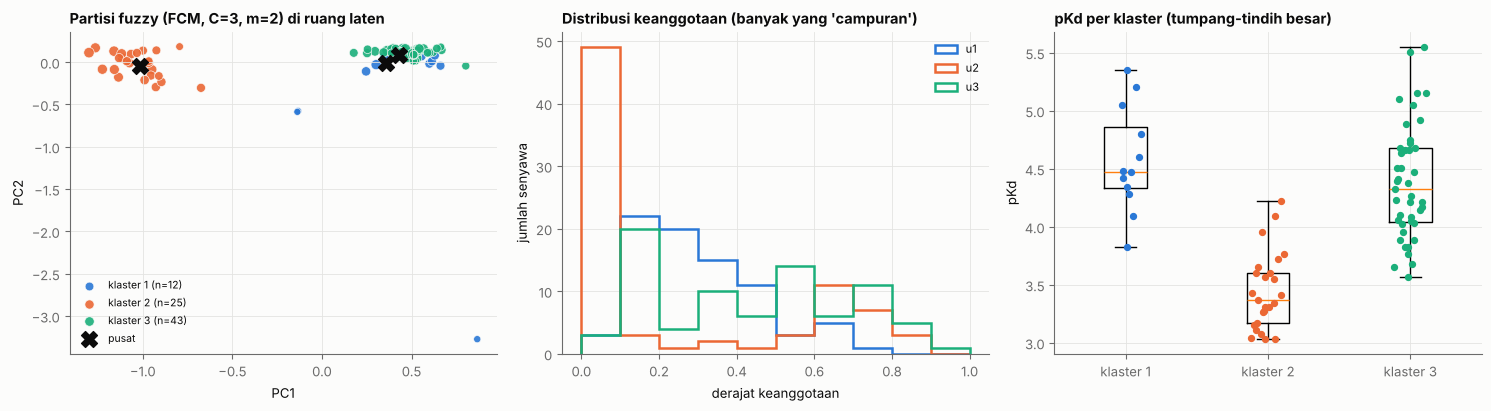

In [9]:
Zf, _, _, _ = latent(X, X[:2]); Vf = fcm(Zf, 3, 2.0); Uf = memb(Zf, Vf, 2.0); u2, s2, vt2 = np.linalg.svd(Zf - Zf.mean(0), full_matrices=False); P2 = (Zf - Zf.mean(0)) @ vt2[:2].T; V2 = (Vf - Zf.mean(0)) @ vt2[:2].T
KC = [C_M1, C_M2, C_M3]; fig, ax = plt.subplots(1, 3, figsize=(15, 4.2)); arg = Uf.argmax(1)
for k in range(3): ax[0].scatter(P2[arg == k, 0], P2[arg == k, 1], s=25 + 60 * (Uf[arg == k, k] - 1 / 3), color=KC[k], edgecolor=SURF, lw=.5, alpha=.9, label=f"klaster {k+1} (n={int((arg==k).sum())})")
ax[0].scatter(V2[:, 0], V2[:, 1], marker="X", s=130, color=INK, zorder=5, label="pusat"); ax[0].set(xlabel="PC1", ylabel="PC2", title="Partisi fuzzy (FCM, C=3, m=2) di ruang laten"); ax[0].legend(fontsize=7.5)
for k in range(3): ax[1].hist(Uf[:, k], bins=np.linspace(0, 1, 11), histtype="step", lw=1.8, color=KC[k], label=f"u{k+1}")
ax[1].set(xlabel="derajat keanggotaan", ylabel="jumlah senyawa", title="Distribusi keanggotaan (banyak yang 'campuran')"); ax[1].legend(fontsize=8)
ax[2].boxplot([y[arg == k] for k in range(3)], tick_labels=[f"klaster {k+1}" for k in range(3)], showfliers=False); [ax[2].scatter(np.full((arg == k).sum(), k + 1) + np.random.RandomState(k).uniform(-.12, .12, (arg == k).sum()), y[arg == k], s=18, color=KC[k], zorder=3) for k in range(3)]
ax[2].set(ylabel="pKd", title="pKd per klaster (tumpang-tindih besar)")
fig.tight_layout(); finish(fig, "02_ilustrasi_fuzzy")

### Grafik 3 — Pemindaian hiperparameter (seleksi vs verifikasi)

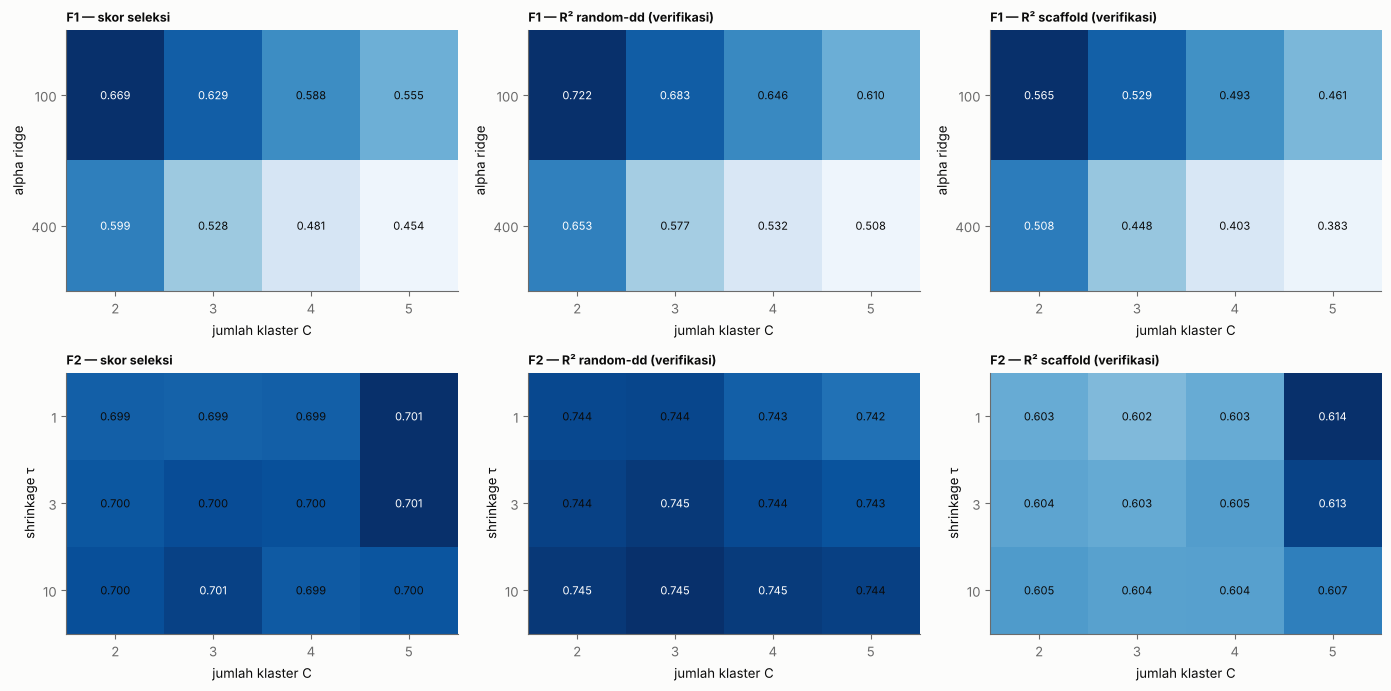

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for r, kd in enumerate(("F1", "F2")):
    g = GR[(GR.kind == kd) & (GR.m == 2.0)]; hs = sorted(g.hyper.unique())
    for c, (col, ttl) in enumerate([("skor_seleksi", "skor seleksi"), ("random_dd", "R² random-dd (verifikasi)"), ("scaffold", "R² scaffold (verifikasi)")]):
        M_ = np.array([[g[(g.C == C) & (g.hyper == h)][col].iloc[0] for C in GRID_C] for h in hs]); im = ax[r, c].imshow(M_, cmap="Blues", aspect="auto", vmin=M_.min() - .01)
        ax[r, c].set_xticks(range(len(GRID_C)), GRID_C); ax[r, c].set_yticks(range(len(hs)), [f"{h:g}" for h in hs]); ax[r, c].set_xlabel("jumlah klaster C"); ax[r, c].set_ylabel("alpha ridge" if kd == "F1" else "shrinkage τ"); ax[r, c].set_title(f"{kd} — {ttl}", fontsize=9); ax[r, c].grid(False)
        for a_ in range(M_.shape[0]):
            for b_ in range(M_.shape[1]): ax[r, c].text(b_, a_, f"{M_[a_, b_]:.3f}", ha="center", va="center", fontsize=8, color=INK if M_[a_, b_] < M_.mean() + .5 * M_.std() else "white")
fig.tight_layout(); finish(fig, "03_grid_fuzzy")

### Grafik 4 — Perbandingan akhir

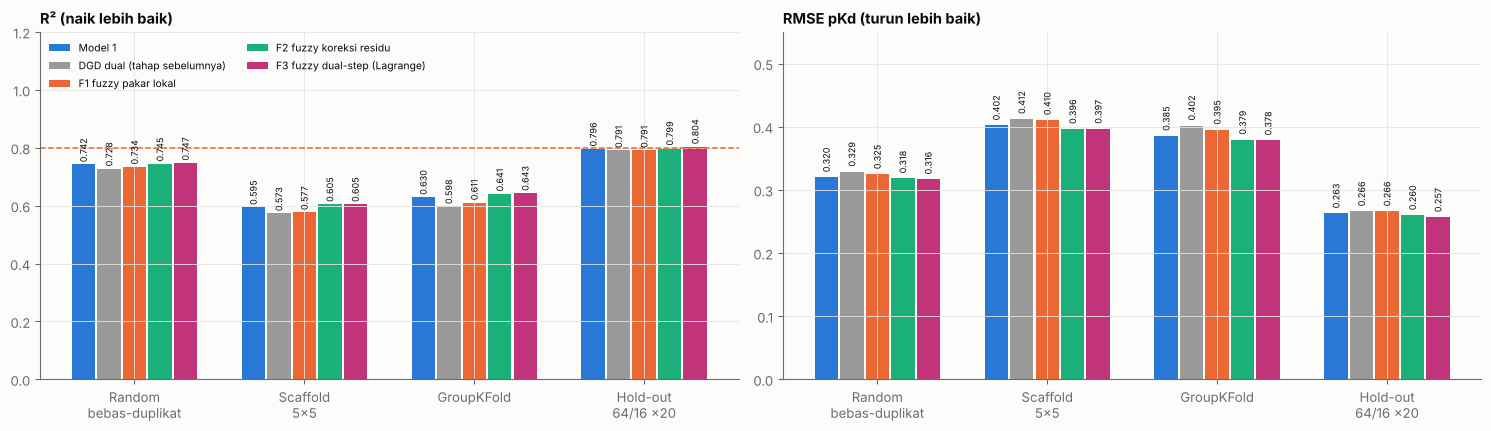

In [11]:
COLS = dict(zip(ENS, [C_M1, C_BASE, C_M2, C_M3, "#c2347a"])); ptag = ["Random\nbebas-duplikat", "Scaffold\n5x5", "GroupKFold", "Hold-out\n64/16 x20"]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4)); xs = np.arange(4); w_ = .15
for a, met in zip(ax, ["R2", "RMSE"]):
    for i, nm in enumerate(ENS):
        sub = MAIN[MAIN.model == nm].set_index("protokol").loc[PROT]; a.bar(xs + (i - 2) * w_, sub[met], w_ * .92, color=COLS[nm], label=nm)
        for xv, vv in zip(xs + (i - 2) * w_, sub[met]): a.text(xv, vv + .008, f"{vv:.3f}", ha="center", rotation=90, fontsize=6.5, va="bottom")
    a.set_xticks(xs, ptag); a.set_title("R² (naik lebih baik)" if met == "R2" else "RMSE pKd (turun lebih baik)")
ax[0].axhline(.8, color=C_M2, ls="--", lw=1.1); ax[0].set_ylim(0, 1.2); ax[1].set_ylim(0, .55); ax[0].legend(fontsize=7.5, ncol=2, loc="upper left", frameon=False)
fig.tight_layout(); finish(fig, "04_perbandingan_akhir")

### Grafik 5 — Observasi vs prediksi

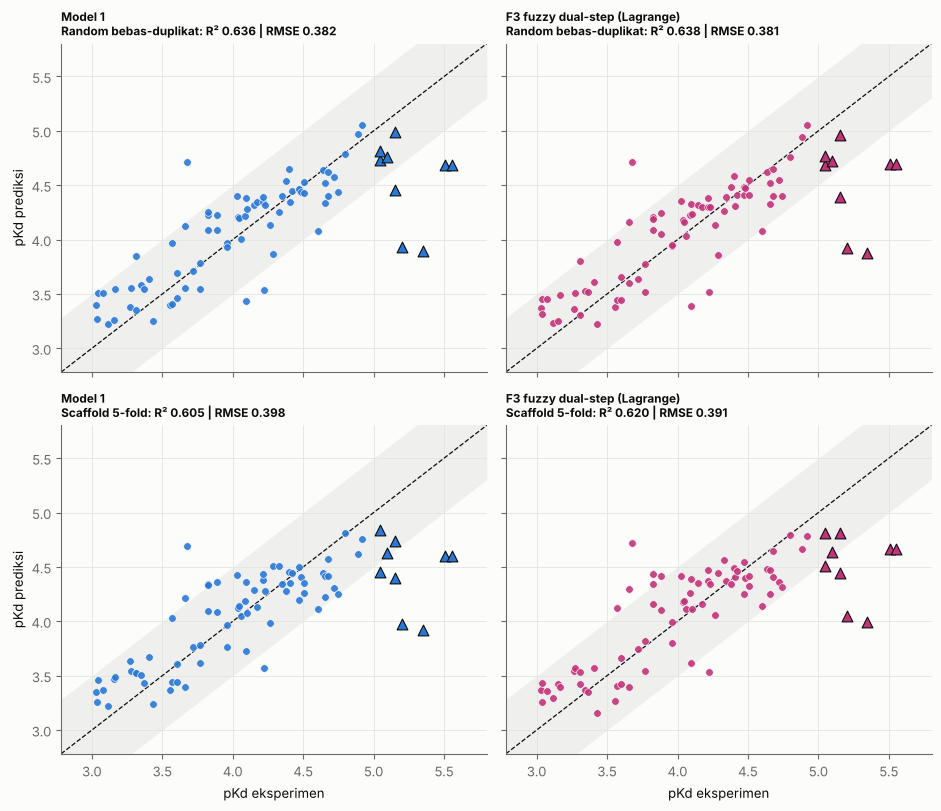

In [12]:
hi = y > 5; lim = [y.min() - .25, y.max() + .25]; sel = ["Model 1", "F3 fuzzy dual-step (Lagrange)"]
fig, ax = plt.subplots(2, 2, figsize=(9.5, 8.2), sharex=True, sharey=True)
for r, (fam, lab) in enumerate([("Rdd_ver:700", "Random bebas-duplikat"), ("S_ver:800", "Scaffold 5-fold")]):
    for c, nm in enumerate(sel):
        a = ax[r, c]; p = oof_(ENS[nm], fam); m_ = metrics(y, p); a.plot(lim, lim, color=INK, lw=.9, ls="--"); a.fill_between(lim, [l - .5 for l in lim], [l + .5 for l in lim], color=GRID, alpha=.5, lw=0)
        a.scatter(y[~hi], p[~hi], s=30, color=COLS[nm], edgecolor=SURF, lw=.5, alpha=.9, zorder=3); a.scatter(y[hi], p[hi], s=60, color=COLS[nm], marker="^", edgecolor=INK, lw=.8, zorder=4)
        a.set_xlim(lim); a.set_ylim(lim); a.set_title(f"{nm}\n{lab}: R² {m_['R2']:.3f} | RMSE {m_['RMSE']:.3f}", fontsize=8.5)
        if c == 0: a.set_ylabel("pKd prediksi")
        if r == 1: a.set_xlabel("pKd eksperimen")
fig.tight_layout(); finish(fig, "05_observasi_vs_prediksi")

## 8. Ringkasan

In [13]:
summ = MAIN.pivot(index="model", columns="protokol", values="R2")[PROT]
for nm in ENS: print(f"  {nm:34s}: " + " | ".join(f"{p.split(' ')[0]} {summ.loc[nm, p]:.3f}{'*' if summ.loc[nm, p] >= .8 else ''}" for p in PROT))
print("  (* = R² >= 0,80)\n\nBerkas keluaran:")
for f in sorted(os.listdir(OUT)):
    if not f.startswith("cache"): print(f"  {OUT}/{f}")

  Model 1                           : Random 0.742 | Scaffold 0.595 | GroupKFold 0.630 | Hold-out 0.796
  DGD dual (tahap sebelumnya)       : Random 0.728 | Scaffold 0.573 | GroupKFold 0.598 | Hold-out 0.791
  F1 fuzzy pakar lokal              : Random 0.734 | Scaffold 0.577 | GroupKFold 0.611 | Hold-out 0.791
  F2 fuzzy koreksi residu           : Random 0.745 | Scaffold 0.605 | GroupKFold 0.641 | Hold-out 0.799
  F3 fuzzy dual-step (Lagrange)     : Random 0.747 | Scaffold 0.605 | GroupKFold 0.643 | Hold-out 0.804*
  (* = R² >= 0,80)

Berkas keluaran:
  hasil_usp5_fuzzy/01_audit_praproses.png
  hasil_usp5_fuzzy/02_ilustrasi_fuzzy.png
  hasil_usp5_fuzzy/03_grid_fuzzy.png
  hasil_usp5_fuzzy/04_perbandingan_akhir.png
  hasil_usp5_fuzzy/05_observasi_vs_prediksi.png
  hasil_usp5_fuzzy/audit_praproses.csv
  hasil_usp5_fuzzy/bobot_F3.csv
  hasil_usp5_fuzzy/bootstrap_berpasangan.csv
  hasil_usp5_fuzzy/diagnostik_koreksi.csv
  hasil_usp5_fuzzy/grid_fuzzy.csv
  hasil_usp5_fuzzy/tabel_perbandinga